# Multi-Fidelity Kolmogorov Arnold Networks
Set of examples to show utility of KAN networks applied to MF datasets

### Initialization
Add the Surrogate Modeling module and setup the notebook

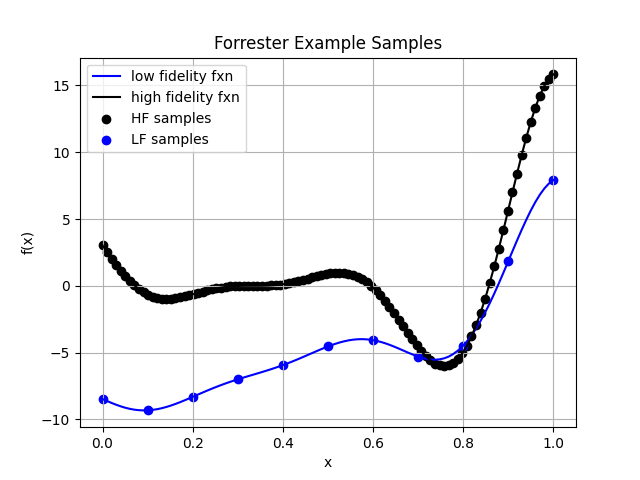

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 5.55e-02 | test_loss: 4.52e-02 | reg: 1.63e+01 | : 100%|█| 20/20 [00:07<00:00,  2.76it


saving model version 0.1


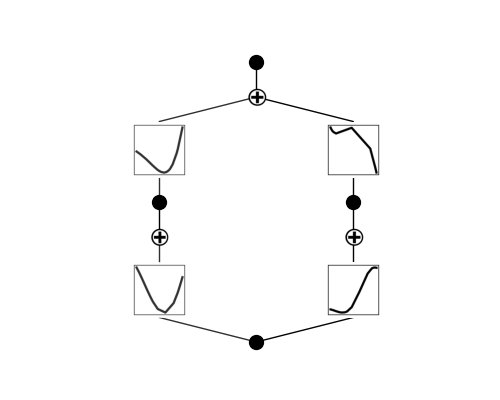

In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np

from SurrogateModels import mfkans

### Function Choice
Set the example function to fit, each has a set high and low fidelity function.

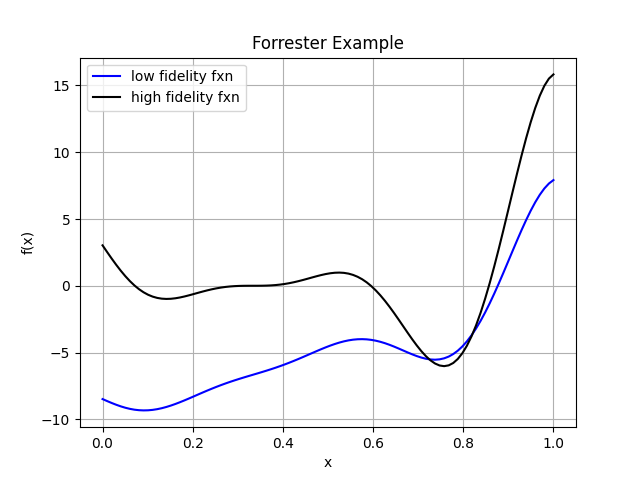

In [2]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name = mf_example.name)
plt.grid()
plt.legend()
plt.show()

### Dataset Generation
Sample the high and low fidelity functions to generate a dataset to fit

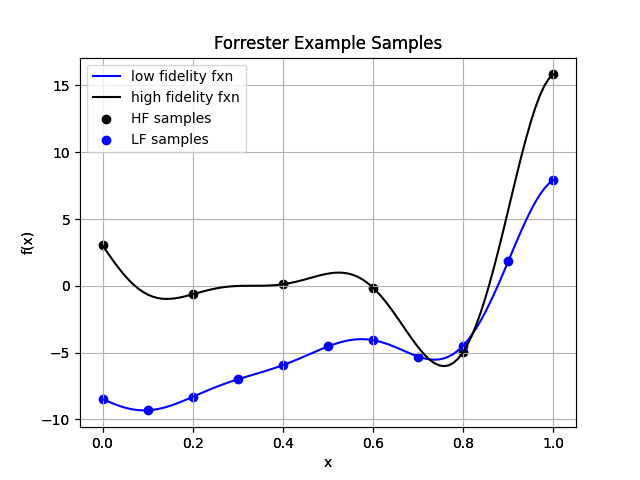

In [3]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11 # number of low fidelity points
n_hf = 6 # number of high fidelity points
n_test = 40 # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.legend()
plt.show()

### Function Fit
Fit the dataset using the KAN network

In [15]:
forrester_model = mfkans.KANModel(X_lf,y_lf,width=[1,1,1,1,1])

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.39e-01 | test_loss: 3.58e+01 | reg: 1.56e+01 | : 100%|█| 20/20 [00:05<00:00,  3.34it

saving model version 0.1


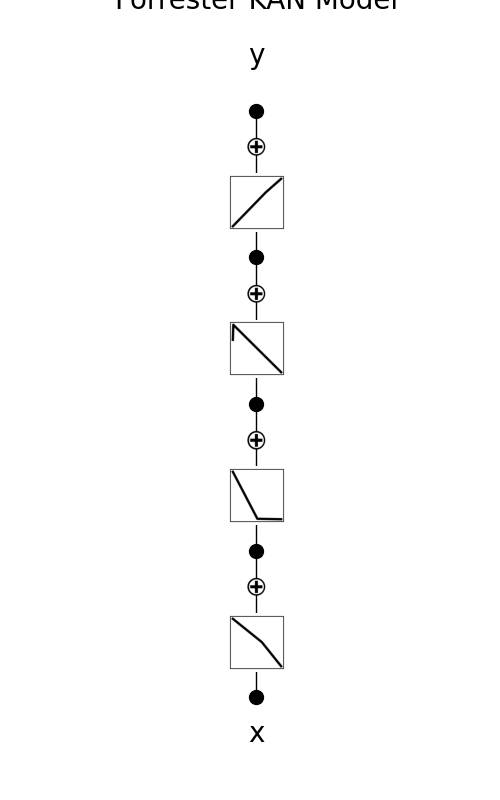

In [17]:
forrester_model.plot(in_vars=['x'],out_vars=['y'],title="Forrester KAN Model")

In [ ]:
forrester_model.plot_model(bounds=mf_example.bounds, name="Forrester KAN Model")

In [5]:
# plot_name = mf_example.name + " LF Kriging Model"

# X_check = np.linspace(0, 1.0, 300, endpoint=True,dtype=np.float32).reshape(-1,1)

# ax = mf_example.plot_low_fidelity(
#     name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
# )
# ax = forrester_kriging_model.plot_data(
#     name=plot_name,
#     color="black",
#     label="LF",
#     marker="s",
#     ax = ax
# )
# forrester_kriging_model.plot_model(
#     mf_example.bounds, name=plot_name, color="red", label="Kriging", linestyle="solid",ax=ax
# )
# plt.grid()
# plt.show()